# Data Quality Assessment (Intentionally Not Fully Cleaned)

**Project:** Employee Attrition Prediction & Retention Intelligence

The dataset has **0 missing values** and **0 duplicate rows**, but that does **not** mean it is logically consistent.
In this section we run cross-column validation rules to find impossible or implausible records.

**Decision:** these records are **flagged and documented, not removed or modified**.
We cannot know which field is wrong (e.g. `Age` or `Years at Company`), so "fixing" them would mean inventing data.
Instead we measure their impact on the target and on model performance (sensitivity check below).

In [3]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

TARGET = "Attrition"
POSITIVE_CLASS = "Left"
RANDOM_STATE = 42


def find_file(name):
    for folder in ["data", ".", ".."]:
        path = Path(folder) / name
        if path.exists():
            return path
    raise FileNotFoundError(f"{name} not found. Put it in ./data/ or next to this notebook.")


train = pd.read_csv(find_file("train.csv"))
test = pd.read_csv(find_file("test.csv"))
full = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)

print(f"train: {train.shape} | test: {test.shape} | combined: {full.shape}")
print("Missing values :", int(full.drop(columns='split').isna().sum().sum()))
print("Duplicate rows :", int(full.drop(columns=['split', 'Employee ID']).duplicated().sum()))

train: (59598, 24) | test: (14900, 24) | combined: (74498, 25)
Missing values : 0
Duplicate rows : 0


## 1. Validation rules

| Rule | Logic | Why it is a problem |
|------|-------|---------------------|
| **R1** | `Age - Years at Company < 16` | Implies the employee joined the company before age 16 |
| **R2** | `Education Level == PhD` and `Age < 24` | A PhD this early is highly implausible |
| **R3** | `Job Level == Senior` and `Years at Company < 2` | Senior level with almost no tenure (possible for external hires, so treated as *suspicious*, not impossible) |

In [4]:
full["start_age"] = full["Age"] - full["Years at Company"]

rules = {
    "R1: Joined company before age 16": full["start_age"] < 16,
    "R2: PhD holder younger than 24": (full["Education Level"] == "PhD") & (full["Age"] < 24),
    "R3: Senior with < 2 years tenure": (full["Job Level"] == "Senior") & (full["Years at Company"] < 2),
}

summary = pd.DataFrame(
    {
        "Rule": list(rules.keys()),
        "Affected rows": [int(m.sum()) for m in rules.values()],
        "% of dataset": [round(m.mean() * 100, 2) for m in rules.values()],
    }
)
display(summary)

# Context for R2 and R3: share within the relevant group
phd = full["Education Level"] == "PhD"
senior = full["Job Level"] == "Senior"
print(f"R2 context: {rules['R2: PhD holder younger than 24'].sum():,} of {phd.sum():,} PhD holders are under 24")
print(f"R3 context: {rules['R3: Senior with < 2 years tenure'].sum():,} of {senior.sum():,} Senior employees have < 2 years tenure")

full["n_violations"] = sum(m.astype(int) for m in rules.values())
full["any_violation"] = full["n_violations"] > 0

print(f"\nRows violating at least one rule: {full['any_violation'].sum():,} ({full['any_violation'].mean():.1%})")
print(f"Rows violating two or more rules: {(full['n_violations'] >= 2).sum():,}")

,Rule,Affected rows,% of dataset
0,R1: Joined company before age 16,23902,32.08
1,R2: PhD holder younger than 24,525,0.70
2,R3: Senior with < 2 years tenure,611,0.82


R2 context: 525 of 3,817 PhD holders are under 24
R3 context: 611 of 15,040 Senior employees have < 2 years tenure

Rows violating at least one rule: 24,689 (33.1%)
Rows violating two or more rules: 349


## 2. How extreme is the R1 violation?

If the data were realistic, the implied age at joining (`Age - Years at Company`) would rarely be below 16.

Implied age at joining (Age - Years at Company):


,value
count,74498.00
mean,22.81
std,11.24
min,8.00
25%,14.00
50%,20.00
75%,30.00
max,58.00


start_age < 0  (impossible)  : 0
start_age < 10 (very extreme): 5898
start_age < 16               : 23902


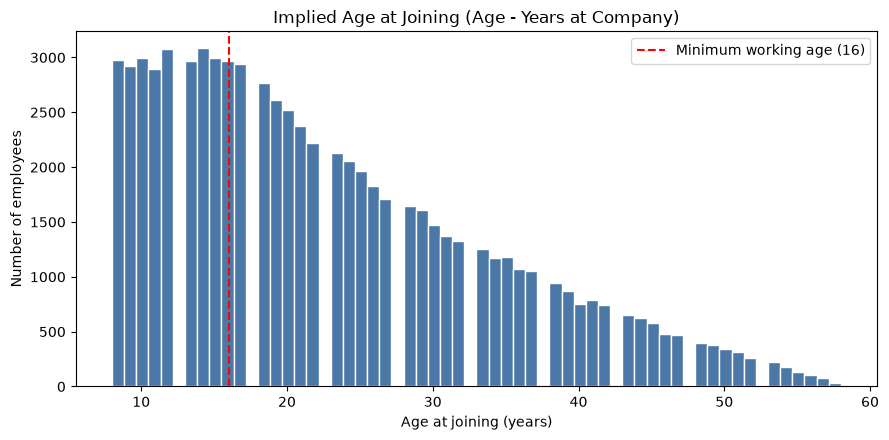

In [5]:
print("Implied age at joining (Age - Years at Company):")
display(full["start_age"].describe().round(2).to_frame("value"))

print("start_age < 0  (impossible)  :", int((full["start_age"] < 0).sum()))
print("start_age < 10 (very extreme):", int((full["start_age"] < 10).sum()))
print("start_age < 16               :", int((full["start_age"] < 16).sum()))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(full["start_age"], bins=60, color="#4C78A8", edgecolor="white")
ax.axvline(16, color="red", linestyle="--", label="Minimum working age (16)")
ax.set_title("Implied Age at Joining (Age - Years at Company)")
ax.set_xlabel("Age at joining (years)")
ax.set_ylabel("Number of employees")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Do the inconsistent rows behave differently on the target?

If flagged rows had a very different attrition rate, removing them would change what the model learns.
(Labels exist only in `train.csv`.)

In [6]:
labeled = full[full["split"] == "train"].copy()
labeled["y"] = (labeled[TARGET] == POSITIVE_CLASS).astype(int)

by_flag = labeled.groupby("any_violation")["y"].agg(rows="count", attrition_rate="mean")
by_flag["attrition_rate"] = (by_flag["attrition_rate"] * 100).round(2)
by_flag.index = by_flag.index.map({False: "Consistent rows", True: "Flagged rows"})
display(by_flag)

per_rule = pd.DataFrame(
    {
        name: {
            "rows": int(m[labeled.index].sum()),
            "attrition_rate_%": round(labeled.loc[m[labeled.index], "y"].mean() * 100, 2),
        }
        for name, m in rules.items()
    }
).T
display(per_rule)

,rows,attrition_rate
any_violation,,
Consistent rows,39926,48.10
Flagged rows,19672,46.43


,rows,attrition_rate_%
R1: Joined company before age 16,19050.0,47.08
R2: PhD holder younger than 24,419.0,30.55
R3: Senior with < 2 years tenure,476.0,26.05


## 4. Sensitivity check: does the model depend on these rows?

We compare 5-fold stratified CV ROC-AUC (Gradient Boosting, same family as the final model) in three setups.
A **sample of 15,000 rows** is used so the cell runs in about a minute; this is a quick diagnostic, not the final evaluation.

In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

sample = labeled.sample(15000, random_state=RANDOM_STATE)

drop_cols = [TARGET, "y", "split", "Employee ID", "start_age", "n_violations", "any_violation"]
X_base = pd.get_dummies(sample.drop(columns=drop_cols), drop_first=True)
y = sample["y"]
flag = sample["any_violation"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)


def cv_auc(X, y):
    return cross_val_score(gb, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)


results = {}
results["A) All rows (as-is)"] = cv_auc(X_base, y)
results["B) Only consistent rows"] = cv_auc(X_base[~flag], y[~flag])
results["C) All rows + 'flagged' feature"] = cv_auc(X_base.assign(flagged=flag.astype(int)), y)

sens = pd.DataFrame(
    {k: {"ROC-AUC mean": v.mean().round(4), "std": v.std().round(4)} for k, v in results.items()}
).T
display(sens)

,ROC-AUC mean,std
A) All rows (as-is),0.8422,0.0072
B) Only consistent rows,0.8391,0.0033
C) All rows + 'flagged' feature,0.8422,0.0071


## 5. Conclusion and decision

**Findings (from the numbers above)**

- **Missing values / duplicates:** none, but the data is **not** logically clean.
- **R1:** 23,902 records (32.1%) imply the employee joined the company before age 16, with the youngest implied joining age at 8. This looks like an artifact of how the synthetic data was generated, not a data-entry error we could repair.
- **R2 / R3:** 525 of 3,817 PhD holders are under 24, and 611 of 15,040 Senior employees have under 2 years of tenure. These flagged groups also show a much lower attrition rate than the rest of the data (see Section 3), so they are not random noise; they follow a pattern in the generated data.
- **Overall:** 24,689 rows (33.1%) violate at least one rule.

**Decision: the records are retained unchanged**, because:

1. we cannot determine which column is wrong, so any correction would be invented data;
2. the same pattern appears in both train and test, so removing it would make training data less representative of the data the model is scored on;
3. the sensitivity check (Section 4) compares model performance with and without these rows, so the choice is backed by evidence rather than assumption.

**Limitations**

- In a real deployment these rules should be enforced as validation checks at the data source, and the HR system owners asked for the correct values.
- The dataset is synthetic, so patterns describe this dataset and the trained model, not causal facts about real employees.